# 🐱🐶 Cats vs Dogs Classification Using Support Vector Machine (SVM)

## Prodigy InfoTech — Machine Learning Internship
### Task 03

---

## 📌 Project Overview

This project implements a Support Vector Machine (SVM) to classify images of cats and dogs using image processing and machine learning techniques.

The project explores RGB pixel features and Histogram of Oriented Gradients (HOG) features, comparing Linear SVM and RBF Kernel SVM models.

## 🎯 Objectives

- Load and explore the Cats vs Dogs image dataset.
- Preprocess images and extract numerical features.
- Implement Linear SVM and RBF Kernel SVM classifiers.
- Evaluate model performance using accuracy, precision, recall, F1-score, and confusion matrices.
- Compare model performance through visualization.
- Predict the class of new images.

## 🛠️ Technologies Used

- Python
- Google Colab
- NumPy
- Matplotlib
- Scikit-learn
- Scikit-image
- Pillow
- KaggleHub

In [1]:
!pip install -q kagglehub

In [2]:
from google.colab import userdata

try:
    token = userdata.get('KAGGLE_API_TOKEN')
    if token:
        print("Success! Kaggle token is configured.")
    else:
        print("Kaggle token is empty.")
except Exception:
    print("Kaggle token not found. We need to configure it.")

Success! Kaggle token is configured.


In [4]:
import kagglehub

# Download the Cats vs Dogs dataset
path = kagglehub.dataset_download("salader/dogsvscats")

print("Dataset downloaded successfully!")
print("Dataset location:", path)

Using Colab cache for faster access to the 'dogsvscats' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/dogsvscats


In [5]:
import os

# Dataset path
dataset_path = "/kaggle/input/dogsvscats"

# Display folders and files
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            print("  " * (level + 1) + f"Number of files: {len(files)}")

dogsvscats/
  test/
    dogs/
      Number of files: 2500
    cats/
      Number of files: 2500
  train/
    dogs/
      Number of files: 10000
    cats/
      Number of files: 10000
  catsvsdogs/
    test/
      Number of files: 0
    train/
      Number of files: 0


Number of cat images: 10000
Number of dog images: 10000


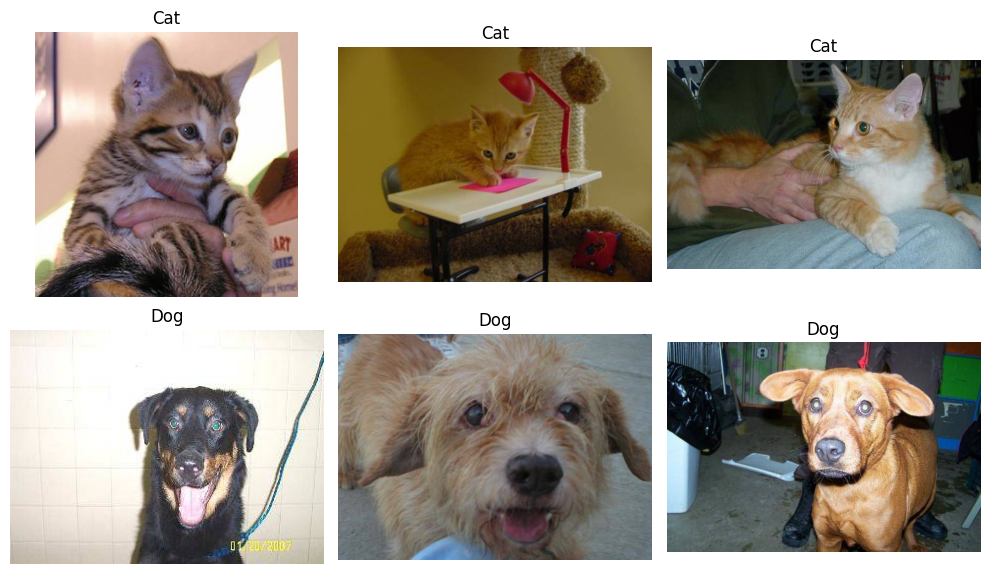

In [6]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Dataset folders
train_path = "/kaggle/input/dogsvscats/train"

cats_path = os.path.join(train_path, "cats")
dogs_path = os.path.join(train_path, "dogs")

# Get image filenames
cat_images = os.listdir(cats_path)
dog_images = os.listdir(dogs_path)

print("Number of cat images:", len(cat_images))
print("Number of dog images:", len(dog_images))

# Display sample images
fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for i in range(3):
    img = Image.open(os.path.join(cats_path, cat_images[i]))
    axes[0, i].imshow(img)
    axes[0, i].set_title("Cat")
    axes[0, i].axis("off")

for i in range(3):
    img = Image.open(os.path.join(dogs_path, dog_images[i]))
    axes[1, i].imshow(img)
    axes[1, i].set_title("Dog")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [7]:
import os
import random
import numpy as np
from PIL import Image

# Dataset paths
train_path = "/kaggle/input/dogsvscats/train"

cats_path = os.path.join(train_path, "cats")
dogs_path = os.path.join(train_path, "dogs")

# Number of images per class
SAMPLES_PER_CLASS = 500

# Resize images
IMG_SIZE = 64

# Reproducibility
random.seed(42)

# Select a small subset of images
cat_images = random.sample(os.listdir(cats_path), SAMPLES_PER_CLASS)
dog_images = random.sample(os.listdir(dogs_path), SAMPLES_PER_CLASS)

X = []
y = []

# Process cat images (label 0)
for filename in cat_images:
    image_path = os.path.join(cats_path, filename)

    try:
        image = Image.open(image_path).convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE))

        X.append(np.array(image).flatten())
        y.append(0)

    except Exception:
        continue

# Process dog images (label 1)
for filename in dog_images:
    image_path = os.path.join(dogs_path, filename)

    try:
        image = Image.open(image_path).convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE))

        X.append(np.array(image).flatten())
        y.append(1)

    except Exception:
        continue

# Convert to NumPy arrays
X = np.array(X, dtype=np.uint8)
y = np.array(y)

print("Image preprocessing completed!")
print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Cat images:", np.sum(y == 0))
print("Dog images:", np.sum(y == 1))

Image preprocessing completed!
Feature matrix shape: (1000, 12288)
Label array shape: (1000,)
Cat images: 500
Dog images: 500


In [8]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train-test split completed!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Train-test split completed!
X_train shape: (800, 12288)
X_test shape: (200, 12288)
y_train shape: (800,)
y_test shape: (200,)


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# Create the SVM model
svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(C=1.0, random_state=42, max_iter=5000)
)

# Train the model
print("Training SVM model... Please wait.")

svm_model.fit(X_train, y_train)

print("SVM model training completed!")

Training SVM model... Please wait.
SVM model training completed!


Model Accuracy: 60.50%

Classification Report:
              precision    recall  f1-score   support

         Cat       0.60      0.62      0.61       100
         Dog       0.61      0.59      0.60       100

    accuracy                           0.60       200
   macro avg       0.61      0.60      0.60       200
weighted avg       0.61      0.60      0.60       200



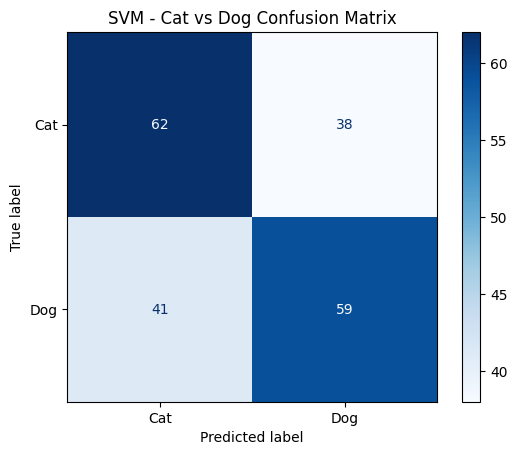

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on unseen test images
y_pred = svm_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Cat", "Dog"]
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SVM - Cat vs Dog Confusion Matrix")
plt.show()


In [11]:
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
import numpy as np

print("Extracting HOG features... Please wait.")

# Convert flattened RGB images back to 64x64x3 images
X_images = X.reshape(-1, 64, 64, 3)

# Extract HOG features from each image
X_hog = []

for image in X_images:
    gray_image = rgb2gray(image)

    features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    X_hog.append(features)

X_hog = np.array(X_hog)

print("HOG feature extraction completed!")
print("HOG feature matrix shape:", X_hog.shape)

Extracting HOG features... Please wait.
HOG feature extraction completed!
HOG feature matrix shape: (1000, 1764)


Training SVM with HOG features...
HOG-based SVM training completed!

HOG-SVM Accuracy: 60.50%

Classification Report:
              precision    recall  f1-score   support

         Cat       0.61      0.60      0.60       100
         Dog       0.60      0.61      0.61       100

    accuracy                           0.60       200
   macro avg       0.61      0.60      0.60       200
weighted avg       0.61      0.60      0.60       200



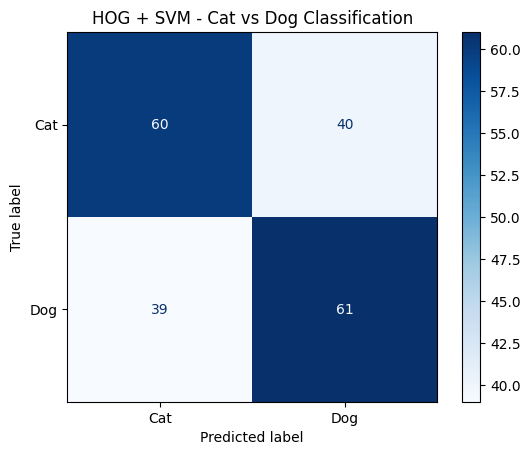

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Split HOG features into training and testing sets
X_train_hog, X_test_hog, y_train_hog, y_test_hog = train_test_split(
    X_hog,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training SVM with HOG features...")

# Create and train the HOG-based SVM model
hog_svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(C=1.0, random_state=42, max_iter=5000)
)

hog_svm_model.fit(X_train_hog, y_train_hog)

print("HOG-based SVM training completed!")

# Evaluate the model
y_pred_hog = hog_svm_model.predict(X_test_hog)

hog_accuracy = accuracy_score(y_test_hog, y_pred_hog)

print(f"\nHOG-SVM Accuracy: {hog_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test_hog,
        y_pred_hog,
        target_names=["Cat", "Dog"]
    )
)

# Display confusion matrix
ConfusionMatrixDisplay.from_estimator(
    hog_svm_model,
    X_test_hog,
    y_test_hog,
    display_labels=["Cat", "Dog"],
    cmap="Blues",
    values_format="d"
)

plt.title("HOG + SVM - Cat vs Dog Classification")
plt.show()

In [13]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Create RBF Kernel SVM
rbf_svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale")
)

print("Training RBF Kernel SVM... Please wait.")

# Train model using HOG features
rbf_svm_model.fit(X_train_hog, y_train_hog)

print("RBF SVM training completed!")

# Make predictions
y_pred_rbf = rbf_svm_model.predict(X_test_hog)

# Calculate accuracy
rbf_accuracy = accuracy_score(y_test_hog, y_pred_rbf)

print(f"\nRBF SVM Accuracy: {rbf_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test_hog,
        y_pred_rbf,
        target_names=["Cat", "Dog"]
    )
)

Training RBF Kernel SVM... Please wait.
RBF SVM training completed!

RBF SVM Accuracy: 69.00%

Classification Report:
              precision    recall  f1-score   support

         Cat       0.70      0.67      0.68       100
         Dog       0.68      0.71      0.70       100

    accuracy                           0.69       200
   macro avg       0.69      0.69      0.69       200
weighted avg       0.69      0.69      0.69       200



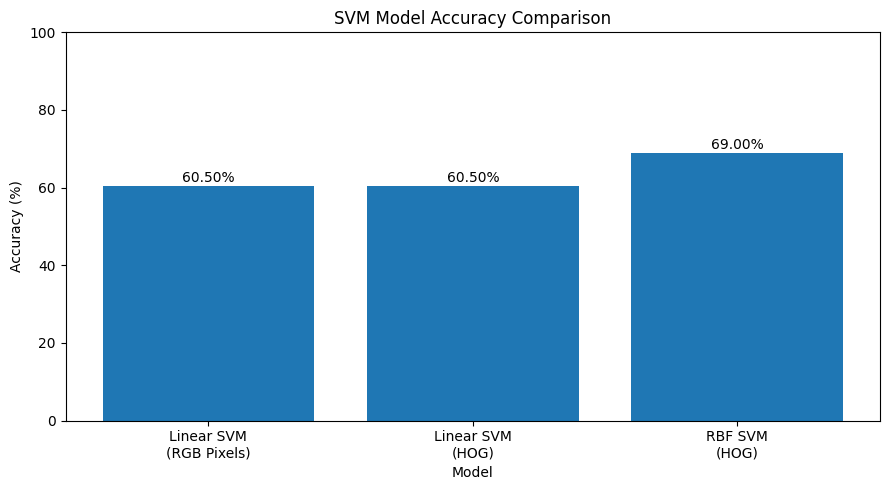

In [14]:
import matplotlib.pyplot as plt

# Model names and their accuracies
model_names = [
    "Linear SVM\n(RGB Pixels)",
    "Linear SVM\n(HOG)",
    "RBF SVM\n(HOG)"
]

accuracies = [
    accuracy * 100,
    hog_accuracy * 100,
    rbf_accuracy * 100
]

# Create comparison chart
plt.figure(figsize=(9, 5))

bars = plt.bar(model_names, accuracies)

plt.title("SVM Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

# Display accuracy values above bars
for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

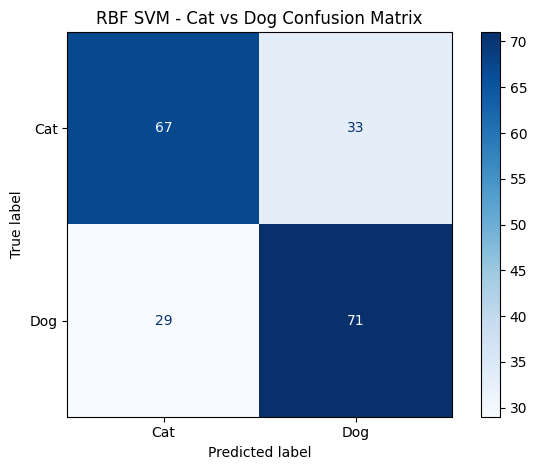

Confusion Matrix:
[[67 33]
 [29 71]]


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm_rbf = confusion_matrix(y_test_hog, y_pred_rbf)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rbf,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("RBF SVM - Cat vs Dog Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm_rbf)

cat.jpg → Predicted: Cat 🐱
dog.jpg → Predicted: Dog 🐶


/tmp/ipykernel_935/3286875321.py:51: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


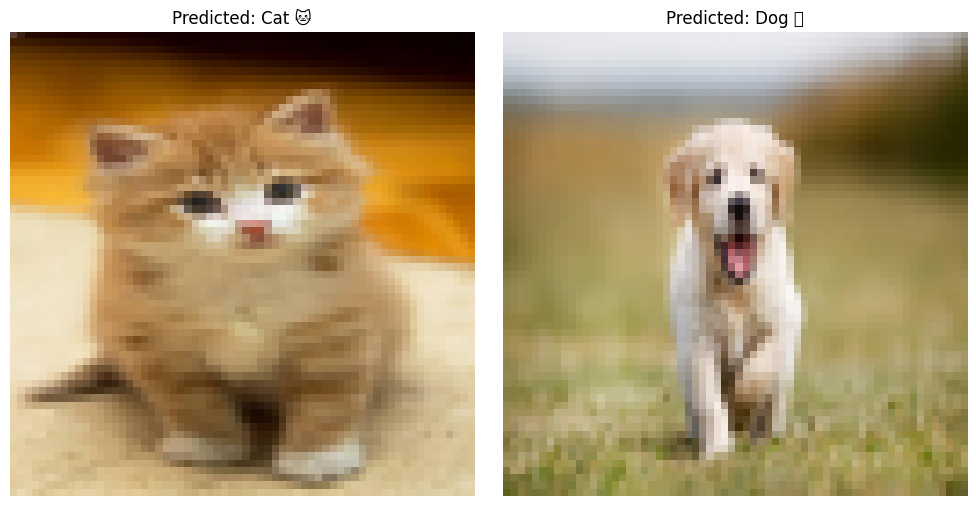

In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from skimage.feature import hog
from skimage.color import rgb2gray

# Image paths
image_paths = ["cat.jpg", "dog.jpg"]

# Class labels
class_names = {
    0: "Cat 🐱",
    1: "Dog 🐶"
}

plt.figure(figsize=(10, 5))

for i, image_path in enumerate(image_paths):

    # Load and preprocess image
    image = Image.open(image_path).convert("RGB")
    image = image.resize((64, 64))

    image_array = np.array(image)
    gray_image = rgb2gray(image_array)

    # Extract HOG features
    features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    # Predict using trained RBF SVM
    prediction = rbf_svm_model.predict(
        features.reshape(1, -1)
    )[0]

    # Display image and prediction
    plt.subplot(1, 2, i + 1)
    plt.imshow(image)
    plt.title(f"Predicted: {class_names[prediction]}")
    plt.axis("off")

    print(f"{image_path} → Predicted: {class_names[prediction]}")

plt.tight_layout()
plt.show()


## 📊 Results and Conclusion

This project implemented Support Vector Machine (SVM) models to classify images of cats and dogs.

### Models Evaluated

| Model | Features | Accuracy |
|---|---|---:|
| Linear SVM | RGB Pixels | 60.50% |
| Linear SVM | HOG Features | 60.50% |
| RBF Kernel SVM | HOG Features | 69.00% |

### Key Findings

- Image preprocessing was performed by resizing images to 64 × 64 pixels.
- HOG (Histogram of Oriented Gradients) was used to extract shape-related features.
- The RBF Kernel SVM achieved the highest accuracy of 69.00% among the evaluated models.
- The best-performing model correctly classified both sample images used for demonstration.

### Conclusion

The experiment demonstrated how Support Vector Machines can be applied to image classification using RGB pixel values and HOG features. The RBF Kernel SVM performed better than the Linear SVM models on the selected test subset.

The evaluation used 1,000 images, with 800 images for training and 200 images for testing. Therefore, the reported accuracy represents performance on this subset and may differ when evaluated on a larger dataset.

Further improvements could include hyperparameter tuning, additional training images, and more advanced image feature extraction techniques.

### Author

**Spandan**  
BTech CSE (AI & ML)  
Machine Learning Internship — Task 03